Assignment_Regression

In [625]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [626]:
car = pd.read_csv('/content/car details v4.csv')
car.head(3)

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0


Data Exploration

In [627]:
df = car.copy()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   object 
 1   Model               2059 non-null   object 
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   object 
 6   Transmission        2059 non-null   object 
 7   Location            2059 non-null   object 
 8   Color               2059 non-null   object 
 9   Owner               2059 non-null   object 
 10  Seller Type         2059 non-null   object 
 11  Engine              1979 non-null   object 
 12  Max Power           1979 non-null   object 
 13  Max Torque          1979 non-null   object 
 14  Drivetrain          1923 non-null   object 
 15  Length              1995 non-null   float64
 16  Width 

In [628]:
df.duplicated().sum()      # No Duplicates

np.int64(0)

In [629]:
df.isnull().sum()

,0
Make,0
Model,0
Price,0
Year,0
Kilometer,0
Fuel Type,0
Transmission,0
Location,0
Color,0
Owner,0


In [630]:
df.isnull().mean()*100

,0
Make,0.000000
Model,0.000000
Price,0.000000
Year,0.000000
Kilometer,0.000000
Fuel Type,0.000000
Transmission,0.000000
Location,0.000000
Color,0.000000
Owner,0.000000


Relationship b/w Features and Target

<Axes: xlabel='Price', ylabel='Count'>

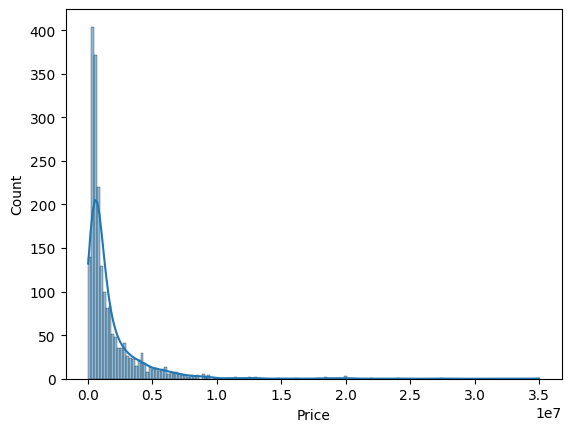

In [631]:
sns.histplot(data=df,x='Price',kde=True)

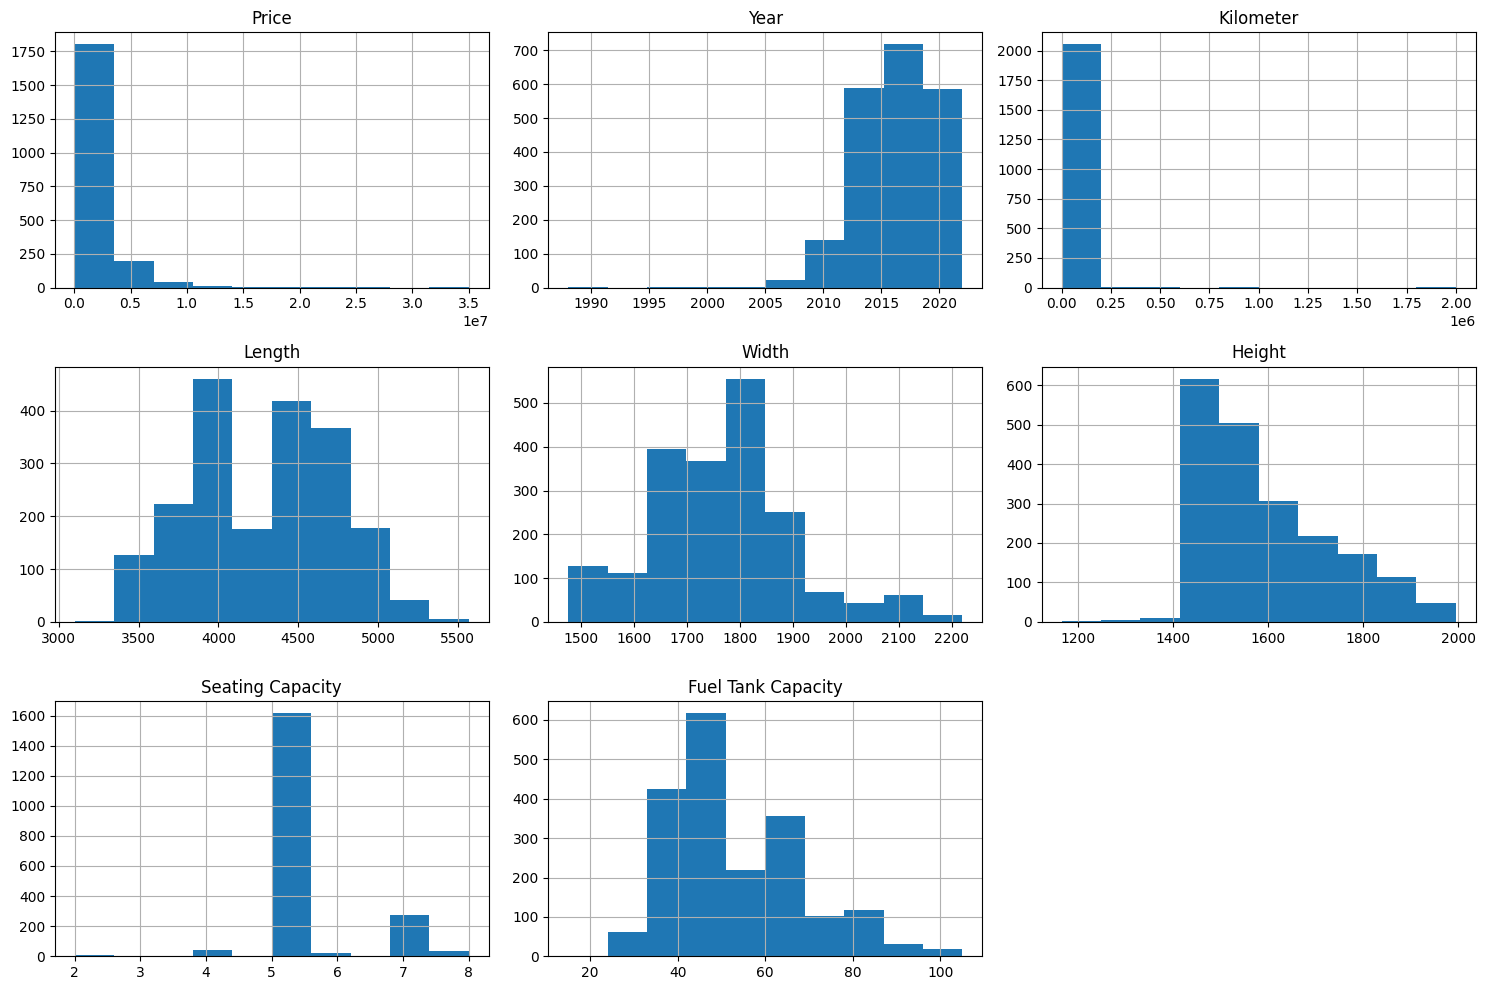

In [632]:
df.select_dtypes(include='number').hist(figsize=(15,10))
plt.tight_layout()
plt.show()

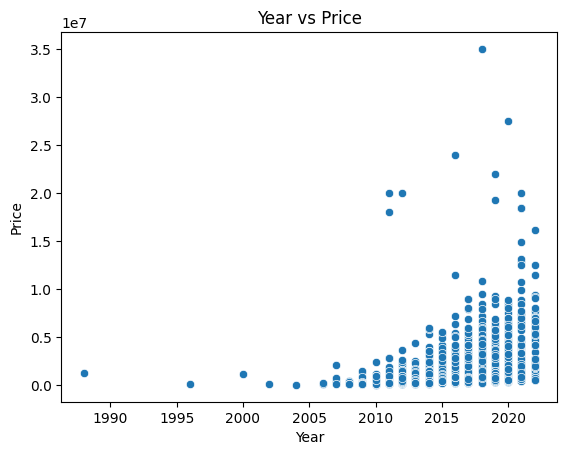

In [633]:
sns.scatterplot(data=df,x='Year',y='Price')
plt.title('Year vs Price')
plt.show()

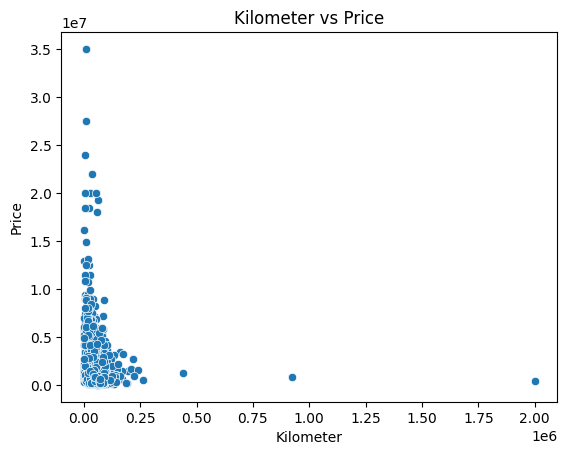

In [634]:
sns.scatterplot(x='Kilometer',y='Price',data=df)
plt.title('Kilometer vs Price')
plt.show()

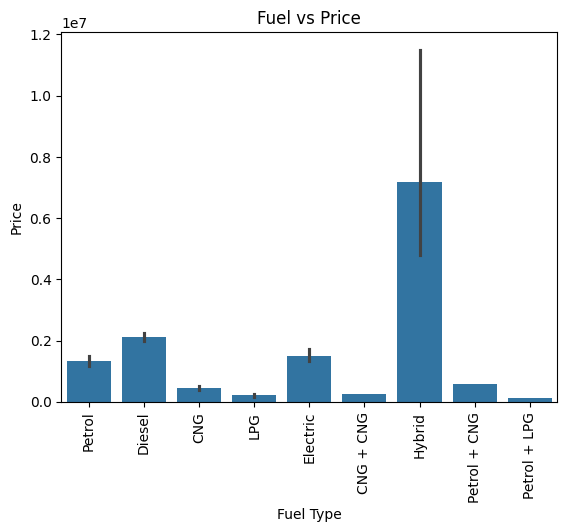

In [635]:
sns.barplot(data=df,x='Fuel Type',y='Price')
plt.xticks(rotation=90)
plt.title('Fuel vs Price')
plt.show()

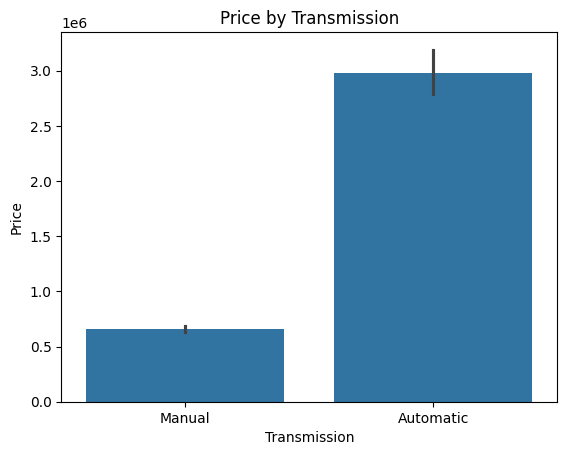

In [636]:
sns.barplot(data=df, x="Transmission", y="Price")
plt.title("Price by Transmission")
plt.show()

In [637]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   object 
 1   Model               2059 non-null   object 
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   object 
 6   Transmission        2059 non-null   object 
 7   Location            2059 non-null   object 
 8   Color               2059 non-null   object 
 9   Owner               2059 non-null   object 
 10  Seller Type         2059 non-null   object 
 11  Engine              1979 non-null   object 
 12  Max Power           1979 non-null   object 
 13  Max Torque          1979 non-null   object 
 14  Drivetrain          1923 non-null   object 
 15  Length              1995 non-null   float64
 16  Width 

Convert numerical columns stored as text

In [638]:
numeric_text_cols = ["Price", "Year", "Kilometer", "Engine","Max Power", "Max Torque", "Length","Width", "Height", "Seating Capacity","Fuel Tank Capacity"]

for i in numeric_text_cols:
    if i in df.columns:
        cleaned = (df[i].astype("string").str.replace(",", "", regex=False).str.extract(r"([-+]?\d*\.?\d+)")[0])
        df[i] = pd.to_numeric(cleaned, errors="coerce")

In [639]:
df.head(2)

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198,87.0,109.0,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248,74.0,190.0,FWD,3995.0,1695.0,1555.0,5.0,42.0


Handling the Missing value


In [640]:
num_cols = df.drop(columns=["Price"]).select_dtypes(include='number')
num_cols

,Year,Kilometer,Engine,Max Power,Max Torque,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,2017,87150,1198,87.0,109.0,3990.0,1680.0,1505.0,5.0,35.0
1,2014,75000,1248,74.0,190.0,3995.0,1695.0,1555.0,5.0,42.0
2,2011,67000,1197,79.0,112.7619,3585.0,1595.0,1550.0,5.0,35.0
3,2019,37500,1197,82.0,113.0,3995.0,1745.0,1510.0,5.0,37.0
4,2018,69000,2393,148.0,343.0,4735.0,1830.0,1795.0,7.0,55.0
...,...,...,...,...,...,...,...,...,...,...
2054,2016,90300,2179,138.0,330.0,4585.0,1890.0,1785.0,7.0,70.0
2055,2014,83000,814,55.0,75.0,3495.0,1550.0,1500.0,5.0,32.0
2056,2013,73000,1196,70.0,102.0,3795.0,1680.0,1427.0,5.0,45.0
2057,2018,60474,1995,188.0,400.0,4936.0,1868.0,1479.0,5.0,65.0


In [641]:
cat_cols = df.select_dtypes(exclude='number').columns
cat_cols

Index(['Make', 'Model', 'Fuel Type', 'Transmission', 'Location', 'Color',
       'Owner', 'Seller Type', 'Drivetrain'],
      dtype='object')

In [642]:
for i in num_cols:
  df[i].fillna(df[i].median(),inplace=True)

for i in cat_cols:
  df[i].fillna(df[i].mode()[0],inplace=True)

/tmp/ipykernel_1098/2496797748.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[i].fillna(df[i].median(),inplace=True)
/tmp/ipykernel_1098/2496797748.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using '

In [643]:
df.isnull().sum()

,0
Make,0
Model,0
Price,0
Year,0
Kilometer,0
Fuel Type,0
Transmission,0
Location,0
Color,0
Owner,0


Outlier Handling

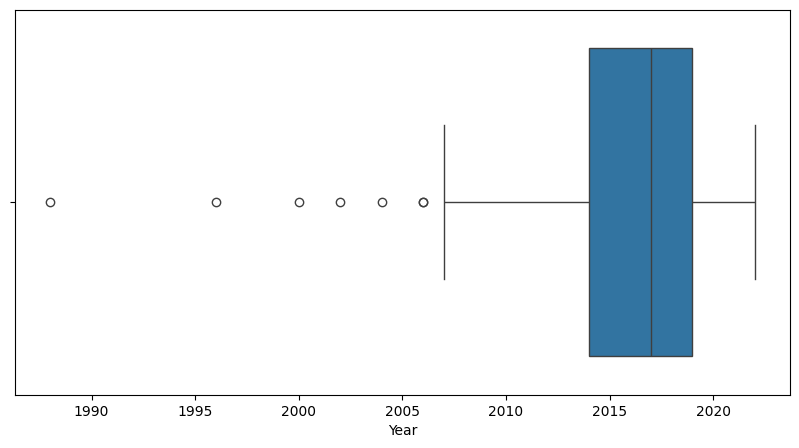

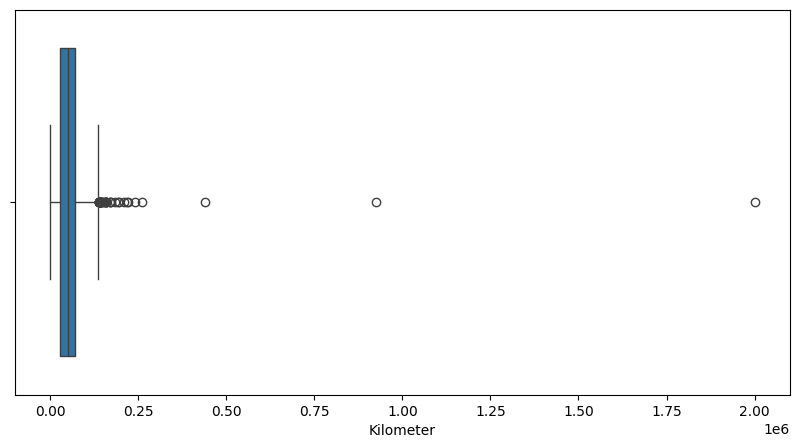

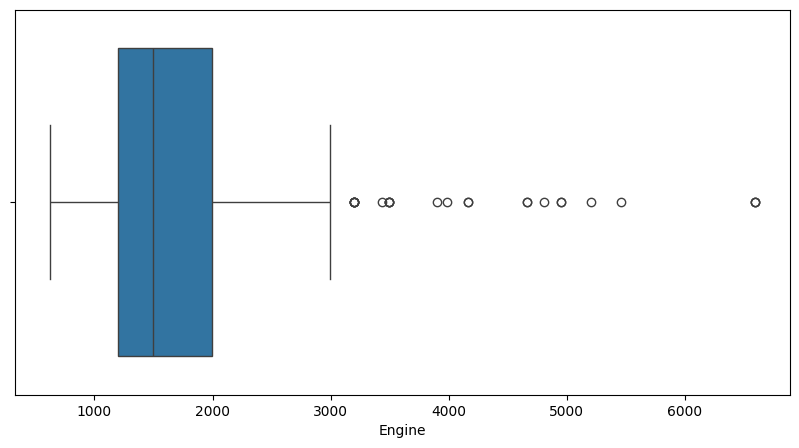

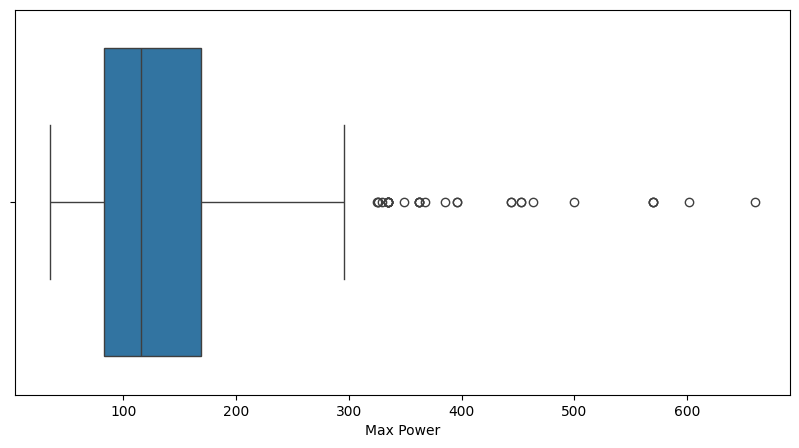

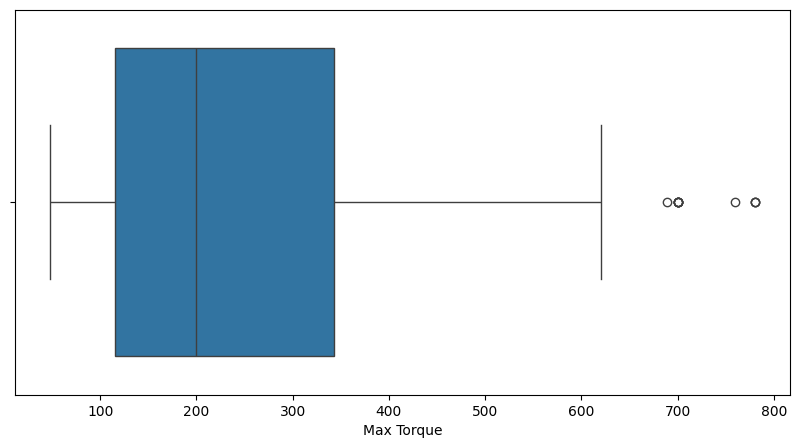

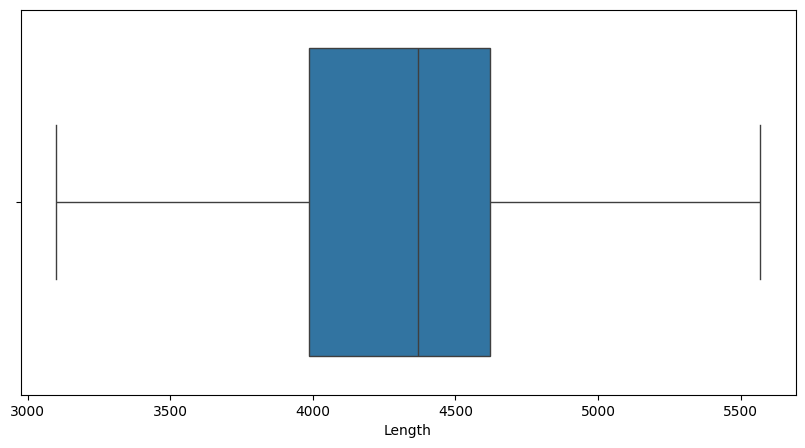

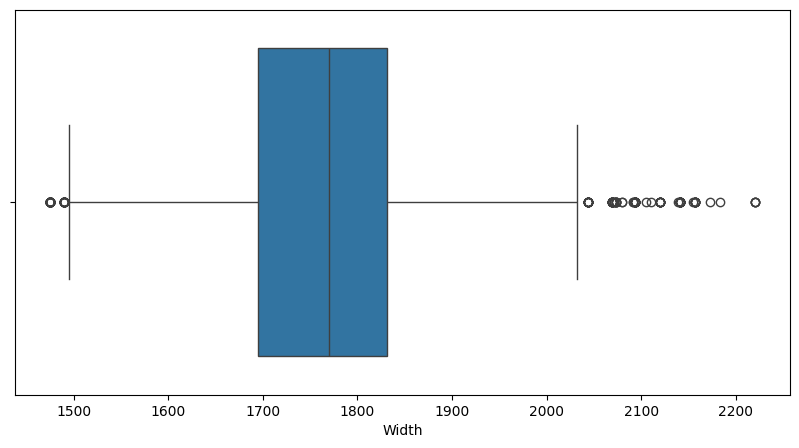

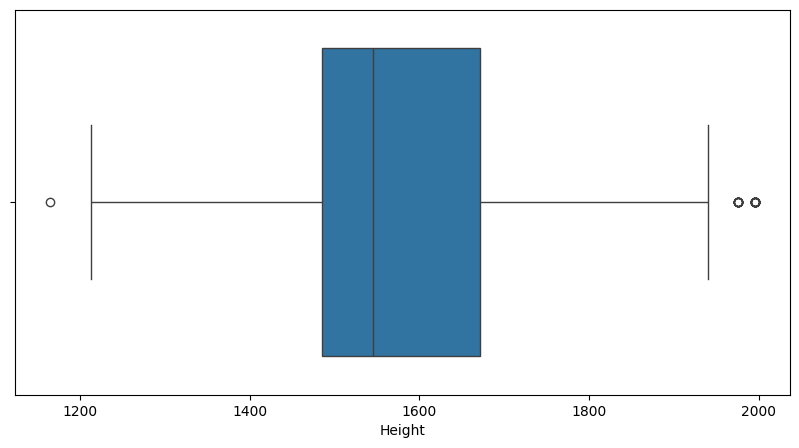

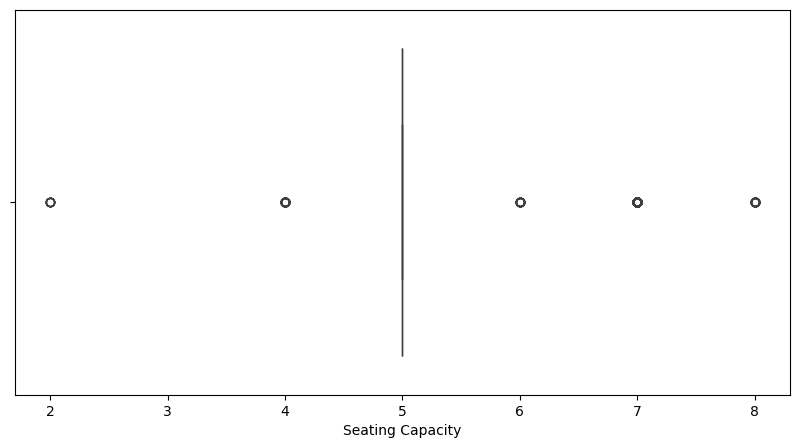

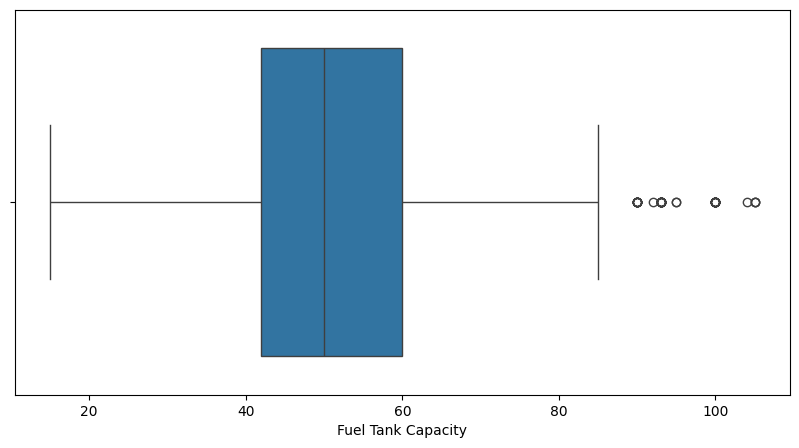

In [644]:
for i in num_cols:
  plt.figure(figsize=(10,5))
  sns.boxplot(data=df,x=i)
  plt.show()


In [645]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(col, "Remaining outliers:", count)

Year Remaining outliers: 7
Kilometer Remaining outliers: 36
Engine Remaining outliers: 25
Max Power Remaining outliers: 31
Max Torque Remaining outliers: 11
Length Remaining outliers: 0
Width Remaining outliers: 182
Height Remaining outliers: 31
Seating Capacity Remaining outliers: 380
Fuel Tank Capacity Remaining outliers: 50


In [646]:
def outlier_cap(df, cols):
  for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

  df[col] = df[col].clip(lower, upper)

  return df

df = outlier_cap(df, num_cols)

In [647]:
df[num_cols.columns].skew()

,0
Year,-0.840685
Kilometer,20.980719
Engine,1.815411
Max Power,2.13171
Max Torque,0.929859
Length,-0.040649
Width,0.311823
Height,0.877625
Seating Capacity,1.515381
Fuel Tank Capacity,0.690685


Handling Skewness

In [648]:
df['Kilometer'] = np.log1p(df['Kilometer'])
df['Max Power'] = np.log1p(df['Max Power'])
df['Engine'] = np.cbrt(df['Engine'])
df['Max Torque'] = np.cbrt(df['Max Torque'])
df['Height'] = np.cbrt(df['Height'])
df['Seating Capacity'] = np.cbrt(df['Seating Capacity'])
df['Fuel Tank Capacity'] = np.cbrt(df['Fuel Tank Capacity'])

In [649]:
df[num_cols.columns].skew()

,0
Year,-0.840685
Kilometer,-3.030742
Engine,0.78367
Max Power,0.371283
Max Torque,0.28847
Length,-0.040649
Width,0.311823
Height,0.765342
Seating Capacity,0.890746
Fuel Tank Capacity,0.340388


Spliting

In [650]:
X = df.drop('Price',axis=1)
y = df['Price']

In [651]:
df.head(3)

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,11.375398,Petrol,Manual,Pune,Grey,First,Corporate,10.620679,4.477337,4.776856,FWD,3990.0,1680.0,11.459847,1.709976,3.271066
1,Maruti Suzuki,Swift DZire VDI,450000,2014,11.225257,Diesel,Manual,Ludhiana,White,Second,Individual,10.766425,4.317488,5.748897,FWD,3995.0,1695.0,11.585376,1.709976,3.476027
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,11.112463,Petrol,Manual,Lucknow,Maroon,First,Individual,10.617723,4.382027,4.83119,FWD,3585.0,1595.0,11.572945,1.709976,3.271066


Encoding

In [652]:
cat_cols

Index(['Make', 'Model', 'Fuel Type', 'Transmission', 'Location', 'Color',
       'Owner', 'Seller Type', 'Drivetrain'],
      dtype='object')

In [653]:
X_enc = pd.get_dummies(X,columns=cat_cols,drop_first=True,dtype='int')
X_enc.head(3)

,Year,Kilometer,Engine,Max Power,Max Torque,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,...,Color_Yellow,Owner_First,Owner_Fourth,Owner_Second,Owner_Third,Owner_UnRegistered Car,Seller Type_Corporate,Seller Type_Individual,Drivetrain_FWD,Drivetrain_RWD
0,2017,11.375398,10.620679,4.477337,4.776856,3990.0,1680.0,11.459847,1.709976,3.271066,...,0,1,0,0,0,0,1,0,1,0
1,2014,11.225257,10.766425,4.317488,5.748897,3995.0,1695.0,11.585376,1.709976,3.476027,...,0,0,0,1,0,0,0,1,1,0
2,2011,11.112463,10.617723,4.382027,4.83119,3585.0,1595.0,11.572945,1.709976,3.271066,...,0,1,0,0,0,0,0,1,1,0


Scaling

In [654]:
from sklearn.preprocessing import StandardScaler

# Identify original numerical columns before encoding
num_cols = X.select_dtypes(include='number').columns

# Create one dataset containing encoded values
X_scaled = X_enc.copy()

# Scale only original numerical columns
scaler = StandardScaler()
X_scaled[num_cols] = scaler.fit_transform(X_enc[num_cols])

# Display the final dataset
X_scaled.head()




,Year,Kilometer,Engine,Max Power,Max Torque,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,...,Color_Yellow,Owner_First,Owner_Fourth,Owner_Second,Owner_Third,Owner_UnRegistered Car,Seller Type_Corporate,Seller Type_Individual,Drivetrain_FWD,Drivetrain_RWD
0,0.170858,0.828588,-0.825128,-0.678565,-1.097522,-0.673941,-0.661496,-0.633142,-0.342477,-1.284243,...,0,1,0,0,0,0,1,0,1,0
1,-0.721270,0.663794,-0.717715,-1.048978,-0.249759,-0.662465,-0.548810,-0.242739,-0.342477,-0.663901,...,0,0,0,1,0,0,0,1,1,0
2,-1.613398,0.539993,-0.827306,-0.899425,-1.050135,-1.603494,-1.300046,-0.281399,-0.342477,-1.284243,...,0,1,0,0,0,0,0,1,1,0
3,0.765609,-0.096983,-0.827306,-0.814117,-1.047171,-0.662465,-0.173193,-0.593716,-0.342477,-1.099147,...,0,1,0,0,0,0,0,1,1,0
4,0.468234,0.572277,1.205221,0.541733,0.841386,1.035978,0.465357,1.523018,2.053834,0.325587,...,0,1,0,0,0,0,0,1,0,1


In [655]:
X_scaled.columns

Index(['Year', 'Kilometer', 'Engine', 'Max Power', 'Max Torque', 'Length',
       'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity',
       ...
       'Color_Yellow', 'Owner_First', 'Owner_Fourth', 'Owner_Second',
       'Owner_Third', 'Owner_UnRegistered Car', 'Seller Type_Corporate',
       'Seller Type_Individual', 'Drivetrain_FWD', 'Drivetrain_RWD'],
      dtype='object', length=1201)

Model Development:

In [656]:
from sklearn.model_selection import train_test_split
y = df['Price']
X =  X_scaled
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)



In [657]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1647, 1201), (412, 1201), (1647,), (412,))

Linear Regression

In [658]:
y_pred = model.predict(X_test)
y_train = model.predict(X_train)


In [659]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Create the model
lr = LinearRegression()

# Train the model
lr.fit(X_train, y_train)

# Predict
y_pred_lr = lr.predict(X_test)

# Evaluate
print("Linear Regression")
print("MSE:", mean_squared_error(y_test, y_pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print("MAE:", mean_absolute_error(y_test, y_pred_lr))
print("R2 Score:", r2_score(y_test, y_pred_lr))

Linear Regression
MSE: 14236821200776.9
RMSE: 3773171.239259742
MAE: 1584878.6343207972
R2 Score: -1.0378251000034644


Lasso

In [660]:
from sklearn.linear_model import Lasso

# Create the model
lasso = Lasso(alpha=1.0, max_iter=10000)

# Train the model
lasso.fit(X_train, y_train)

# Predict
y_pred_lasso = lasso.predict(X_test)

# Evaluate
print("Lasso Regression")
print("MSE:", mean_squared_error(y_test, y_pred_lasso))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lasso)))
print("MAE:", mean_absolute_error(y_test, y_pred_lasso))
print("R2 Score:", r2_score(y_test, y_pred_lasso))

Lasso Regression
MSE: 4568519497883.535
RMSE: 2137409.5297540748
MAE: 653423.8729747682
R2 Score: 0.3460728647674345


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.048e+12, tolerance: 9.105e+11
  model = cd_fast.enet_coordinate_descent(


Ridge

In [661]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Create the model
ridge = Ridge(alpha=1.0)

# Train the model
ridge.fit(X_train, y_train)

# Predict
y_pred_ridge = ridge.predict(X_test)

# Evaluate
print("Ridge Regression")
print("MSE:", mean_squared_error(y_test, y_pred_ridge))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ridge)))
print("MAE:", mean_absolute_error(y_test, y_pred_ridge))
print("R2 Score:", r2_score(y_test, y_pred_ridge))

Ridge Regression
MSE: 2723845159946.7344
RMSE: 1650407.5738879577
MAE: 602355.6537909528
R2 Score: 0.6101152106089873


Decision Tree

In [662]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Create the model
ridge = Ridge(alpha=1.0)

# Train the model
ridge.fit(X_train, y_train)

# Predict
y_pred_ridge = ridge.predict(X_test)

# Evaluate
print("Ridge Regression")
print("MSE:", mean_squared_error(y_test, y_pred_ridge))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ridge)))
print("MAE:", mean_absolute_error(y_test, y_pred_ridge))
print("R2 Score:", r2_score(y_test, y_pred_ridge))

Ridge Regression
MSE: 2723845159946.7344
RMSE: 1650407.5738879577
MAE: 602355.6537909528
R2 Score: 0.6101152106089873


RandomForestRegressor

In [663]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Create the model
rf = RandomForestRegressor(n_estimators=100, random_state=42)

# Train the model
rf.fit(X_train, y_train)

# Predict
y_pred_rf = rf.predict(X_test)

# Evaluate
print("Random Forest Regression")
print("MSE:", mean_squared_error(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("MAE:", mean_absolute_error(y_test, y_pred_rf))
print("R2 Score:", r2_score(y_test, y_pred_rf))



Random Forest Regression
MSE: 1297757829888.7761
RMSE: 1139191.7441277285
MAE: 320205.1426497937
R2 Score: 0.8142419967085729


KNN

In [664]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Create the model
knn = KNeighborsRegressor(n_neighbors=5)

# Train the model
knn.fit(X_train, y_train)

# Predict
y_pred_knn = knn.predict(X_test)

# Evaluate
print("KNN Regression")
print("MSE:", mean_squared_error(y_test, y_pred_knn))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_knn)))
print("MAE:", mean_absolute_error(y_test, y_pred_knn))
print("R2 Score:", r2_score(y_test, y_pred_knn))

KNN Regression
MSE: 2035650223025.3384
RMSE: 1426762.1466191688
MAE: 427190.7925331264
R2 Score: 0.708621815164588


In RandomForestRegressor it is showing Better Result, upto "81%" .
  So RandomForestRegressor is the optimum model.